In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Dense,LSTM
from tensorflow.keras.models import Sequential
from sklearn.metrics import confusion_matrix,mean_squared_error, mean_absolute_error, r2_score

In [2]:
data = pd.read_csv("gold_futures_timeseries.csv")

In [3]:
data.head(10)

,date,open,high,low,close,volume,ma_7,ma_30,ma_90,daily_return,volatility_7,volatility_30,rsi,macd,macd_signal,bb_upper,bb_lower
0,2021-07-15,1828.4,1833.0,1823.4,1831.6,99,1807.8143,1821.0300,1794.8378,1.0204,0.3921,0.9204,77.0256,-5.6307,-12.2447,1825.2034,1753.8266
1,2021-07-16,1814.5,1831.4,1814.5,1830.1,78,1812.3000,1818.4067,1796.4367,-0.0819,0.3943,0.9129,76.7894,-3.1756,-10.4309,1829.3189,1751.5410
2,2021-07-19,1808.7,1813.4,1803.3,1803.3,33,1813.2000,1816.2067,1797.4333,-1.4644,0.7616,0.8746,59.6577,-3.3538,-9.0154,1830.4561,1753.1639
3,2021-07-20,1810.9,1824.0,1810.9,1812.9,128,1814.5286,1813.6200,1798.4033,0.5324,0.7754,0.8516,63.9382,-2.6894,-7.7502,1832.1624,1755.8675
4,2021-07-21,1802.9,1807.0,1800.0,1807.0,135,1815.1571,1810.6367,1799.4156,-0.3254,0.7897,0.8479,69.1730,-2.6088,-6.7220,1833.4198,1756.9701
5,2021-07-22,1805.0,1805.0,1793.6,1793.6,2,1813.0857,1807.2600,1800.1278,-0.7416,0.8287,0.8544,57.5528,-3.5850,-6.0946,1833.4656,1758.2143
6,2021-07-23,1801.4,1801.4,1800.0,1800.0,1,1811.2143,1804.3367,1800.8800,0.3568,0.8355,0.8590,58.7367,-3.7983,-5.6353,1833.6949,1760.0951
7,2021-07-26,1798.7,1802.5,1797.2,1802.5,17,1807.0571,1801.0567,1801.6267,0.1389,0.6926,0.8458,56.7870,-3.7228,-5.2528,1833.8674,1762.4026
8,2021-07-27,1799.5,1803.7,1799.5,1803.7,1,1803.2857,1798.9733,1802.2700,0.0666,0.7000,0.7868,52.3674,-3.5254,-4.9073,1834.0515,1764.6285
9,2021-07-28,1799.5,1799.5,1799.5,1799.5,209783,1802.7429,1796.7433,1802.9067,-0.2329,0.4356,0.7868,51.1563,-3.6657,-4.6590,1833.5281,1767.4218


In [4]:
data=data.drop_duplicates()

In [5]:
data=data.dropna()

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1169 entries, 0 to 1168
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           1169 non-null   object 
 1   open           1169 non-null   float64
 2   high           1169 non-null   float64
 3   low            1169 non-null   float64
 4   close          1169 non-null   float64
 5   volume         1169 non-null   int64  
 6   ma_7           1169 non-null   float64
 7   ma_30          1169 non-null   float64
 8   ma_90          1169 non-null   float64
 9   daily_return   1169 non-null   float64
 10  volatility_7   1169 non-null   float64
 11  volatility_30  1169 non-null   float64
 12  rsi            1169 non-null   float64
 13  macd           1169 non-null   float64
 14  macd_signal    1169 non-null   float64
 15  bb_upper       1169 non-null   float64
 16  bb_lower       1169 non-null   float64
dtypes: float64(15), int64(1), object(1)
memory usage: 15

In [7]:
data=data.drop("date",axis=1)

In [8]:
X=data.drop("volatility_30",axis=1)

In [9]:
y=data["volatility_30"]

In [10]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [11]:
print(X_test.shape)
print(y_test.shape)
print(X_train.shape)
print(y_train.shape)

(234, 15)
(234,)
(935, 15)
(935,)


In [12]:
seq_len = 50
x, Y = [], []
A = len(data) - seq_len
for i in range(A):
    x.append(data.iloc[i:i+seq_len].values)
    Y.append(data.iloc[i+seq_len]["volatility_30"])

In [13]:
x = np.array(X[:1119])  
Y = np.array(Y) 

print(x.shape)
print(Y.shape)

(1119, 15)
(1119,)


In [14]:
model=Sequential()
model.add(LSTM(64, input_shape=(seq_len, 1)))
model.add(Dense(1))
model.compile(
    optimizer='adam',     
    loss='mse',          
    metrics=['mae']       
)

C:\Users\Dineshraj\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [15]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 64)                  │          16,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 16,961 (66.25 KB)

 Trainable params: 16,961 (66.25 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
print(X.shape)
print(x.shape)
print(Y.shape)
print(y.shape)

(1169, 15)
(1119, 15)
(1119,)
(1169,)


In [17]:
model.fit(x,Y,epochs=30,batch_size=32)
print("Training complete")

Epoch 1/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - loss: 0.3299 - mae: 0.3982
Epoch 2/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.1811 - mae: 0.2567
Epoch 3/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1503 - mae: 0.2310
Epoch 4/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1357 - mae: 0.2243
Epoch 5/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.1286 - mae: 0.2212
Epoch 6/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1263 - mae: 0.2235
Epoch 7/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.1249 - mae: 0.2223
Epoch 8/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1238 - mae: 0.2213
Epoch 9/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1227 - mae: 0.2202
Epoch 10/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.1219 - mae: 0.2187
Epoch 11/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.1226 - mae: 0.2219
Epoch 12/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1218 - mae: 0.2231
Epoch 13/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 0

In [18]:
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("MSE:", mse)
print("MAE:", mae)
print("R²:", r2)

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step
MSE: 0.17088998952999743
MAE: 0.27310367533651175
R²: -0.013944404320611614


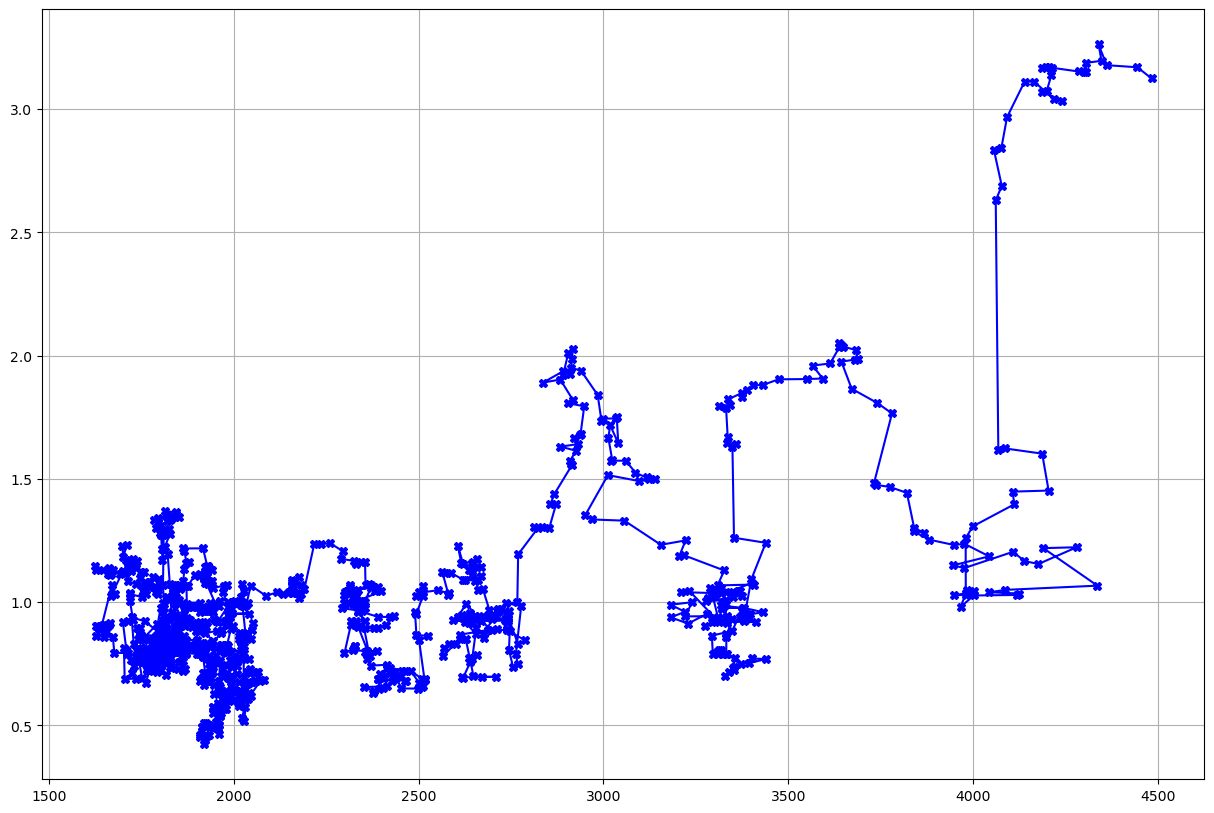

In [31]:
plt.figure(figsize=(15,10))
plt.plot(x[:, 0],Y,color="blue", marker="X")
plt.grid()
plt.show()

In [28]:
print(x.shape)
print(Y.shape)

(1119, 15)
(1119,)


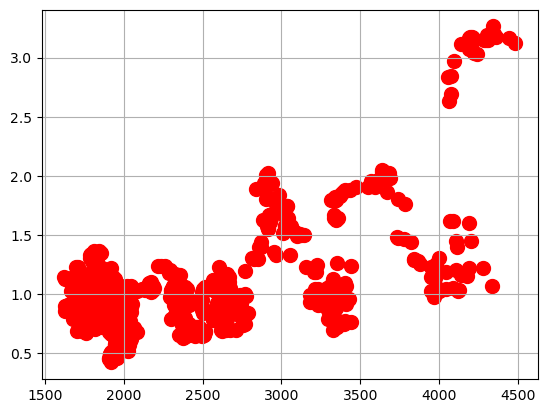

In [30]:
plt.scatter(x[:, 0], Y, color="red", s=100)
plt.grid()
plt.show()

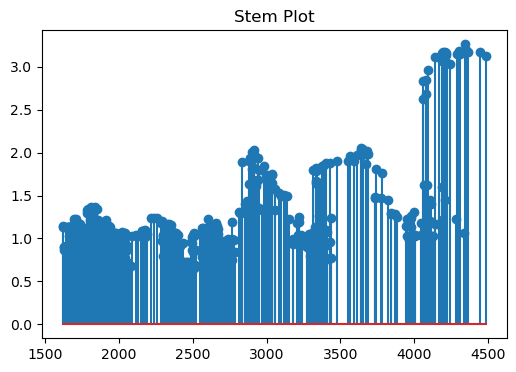

In [33]:
plt.figure(figsize=(6,4))
plt.stem(x[:, 0], Y)
plt.title("Stem Plot")
plt.show()

In [34]:
import joblib
joblib.dump(model,"LSTM_model")
print("Saved")

Saved


In [35]:
New=joblib.load("LSTM_model")

In [36]:
data.to_csv("Output", index=False)

In [38]:
dv=pd.DataFrame([[1927.8, 1942.3, 1918.6, 1935.4, 512, 1925.67, 1915.42, 1899.85, 0.42, 0.76, 62.48, 2.36, 1.91, 1948.12, 1886.74]],
                columns = ["open", "high", "low", "close", "volume", "ma_7", "ma_30", "ma_90", "daily_return", "volatility_7", "rsi", "macd", "macd_signal", "bb_upper", "bb_lower"])

In [39]:
a=New.predict(dv)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 554ms/step


In [40]:
print(A)

1119
